In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
import data_preprocessing.plotting_functions as ABC_plot
import data_preprocessing.ABC_priors_and_functions as ABC
import data_preprocessing.stochastic_systems_models as SSM

SMALL_SIZE = 12
MEDIUM_SIZE = 12
BIGGER_SIZE = 16

plt.rc('font', size=BIGGER_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=BIGGER_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title
plt.rcParams['font.family'] = 'Arial'

In [2]:
#Extracting posterior parameters
params = np.load("C:\\Uni\\Imperial\\Year 1\\First_pet_project\\Project4\\extended_three_pop_ABC\\accepted_extended_three_population_chase_pulse_params.npy")
beta0, beta1, p, mu_d_r, mu_d_y, mu_d_o, mu_a, mu_r, mu_rej, c = params.transpose()

mu_b = np.zeros(len(beta0))
mu_b[mu_d_o != 0] = ((mu_d_r+p*mu_r)*(mu_d_y*mu_d_o + mu_d_y*mu_rej+mu_d_o*mu_a)/((mu_d_o+mu_rej)*(mu_r-mu_d_r)))[mu_d_o != 0]
mu_b[mu_d_o == 0] = ((mu_d_r+p*mu_r)*mu_d_y/(mu_r-mu_d_r))[mu_d_o == 0]

f_y = 1/(1 + mu_b/(mu_d_r + p*mu_r) + mu_a/(mu_d_o + mu_rej))
f_r = (mu_b/(mu_d_r + p*mu_r))*1/(1 + mu_b/(mu_d_r + p*mu_r) + mu_a/(mu_d_o + mu_rej))
f_o = 1-f_y-f_r

pi_y = 1/(1 + (1+p)*mu_b*mu_r/(mu_d_r+p*mu_r)**2 + mu_a*mu_rej/(mu_d_o + mu_rej)**2)

mu_coal =  2 * (pi_y/f_y)**2 * f_r * (mu_r + mu_d_r*p)/(mu_r*p + mu_d_r) * mu_r

m = mu_rej/(mu_rej+mu_d_o)

param = params[6]*1
param[-1]= 0.05

We begin by initialising a mutant at 0.5 heteroplasmy and observing its behaviour after 6 months, under neutral drift, SSD, neutral drift with preferential degradation, and SSD with preferential degradation.

These code blocks take a few minutes to run.

In [3]:
def plot_hets(het_arr):
    time = np.linspace(0,6,51)

    fig, ax = plt.subplots(1,2, figsize = (12,3))
    for traj in het_arr:
        ax[0].plot(time, traj)

    ax[1].plot(time, np.mean(het_arr, axis = 0))

    ax[0].set_xlabel("Time (months)")
    ax[1].set_xlabel("Time (months)")
    ax[0].set_ylabel("Heteroplasmy")

    ax[1].set_ylabel("Heteroplasmy")
    ax[0].set_title("Every trajectory")
    ax[1].set_title("Mean trajectory")

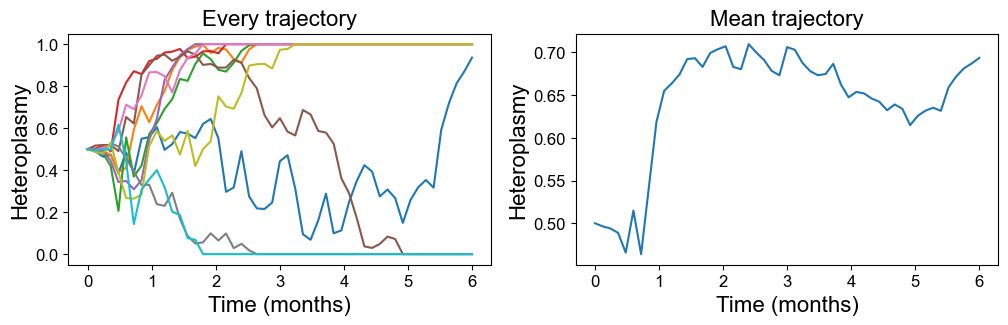

In [4]:
#SSD (delta = 0.3)
het_arr = SSM.extended_three_population_SSD_heteroplasmy_dynamics(param, num_iter = 10, N=100, delta = 0.3, pref_deg_factor=1)
plot_hets(het_arr)

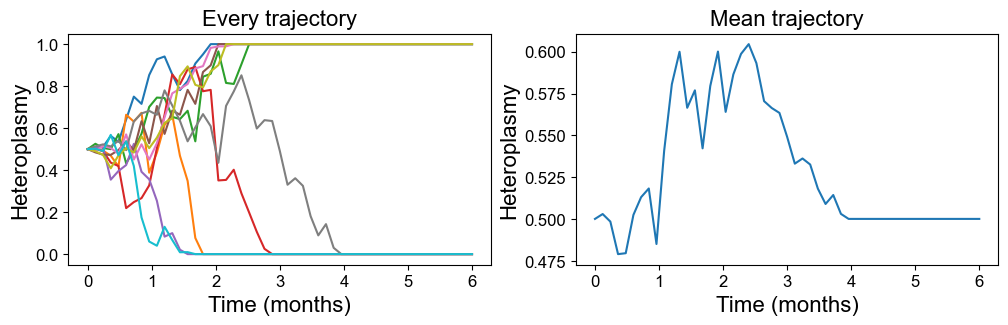

In [5]:
#Neutral drift (delta = 1)
het_arr = SSM.extended_three_population_SSD_heteroplasmy_dynamics(param, num_iter = 10, N=100, delta = 1, pref_deg_factor=1)
plot_hets(het_arr)

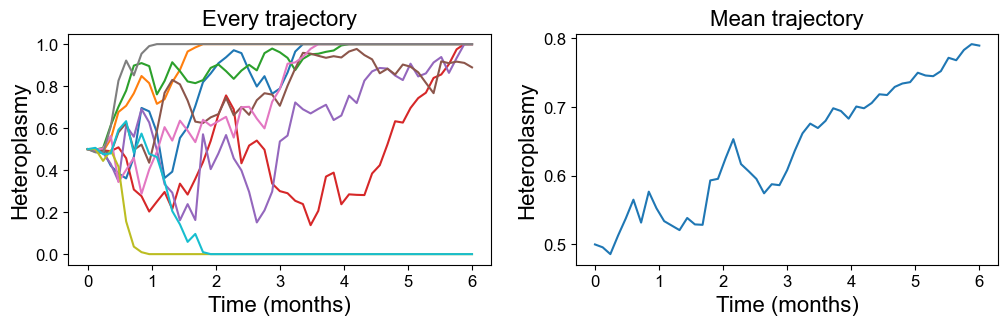

In [6]:
#SSD (delta=0.3) and preferential degradation of mutants (pref_deg_factor = 1.03)
het_arr = SSM.extended_three_population_SSD_heteroplasmy_dynamics(param, num_iter = 10, N=100, delta = 0.3, pref_deg_factor=1.03)
plot_hets(het_arr)

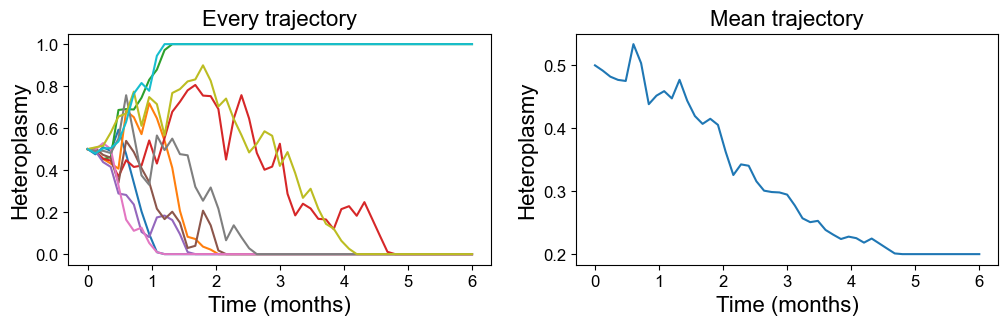

In [7]:
#no SSD (delta=1) and preferential degradation of mutants (pref_deg_factor = 1.03)
het_arr = SSM.extended_three_population_SSD_heteroplasmy_dynamics(param, num_iter = 10, N=100, delta = 1, pref_deg_factor=1.03)
plot_hets(het_arr)

The above was for 10 iterations. If we do the above for 1000 iterations, we obtain:

Text(0, 0.5, 'Heteroplasmy')

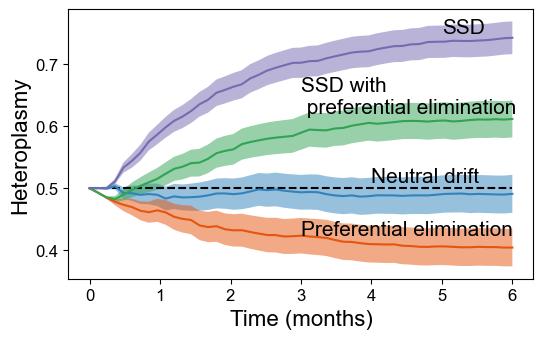

In [ ]:
npd_hets = np.load("./data_preprocessing/SSD_data/posterior_SSD_heteroplasmies.npy")
pd_hets = np.load("./data_preprocessing/SSD_data/posterior_SSD_heteroplasmies_pref_deg.npy")

import matplotlib.colors as mcolors
cmap = plt.get_cmap('tab20c')

plt.figure(1, figsize = (6,3.5))
hex_colors = [mcolors.to_hex(cmap(i)) for i in range(20)]
plt.hlines(0.5,0,6, linestyles = 'dashed', color = "black")

time = np.linspace(0,6,51)
plt.plot(time,pd_hets[0][0], label = "neutral drift", color = hex_colors[0])
plt.plot(time,pd_hets[1][0], label = "preferential elimination", color = hex_colors[4])
plt.plot(time,pd_hets[2][0], label = "SSD with preferential degradation", color = hex_colors[8])
plt.plot(time,npd_hets[6][0], label = "SSD", color = hex_colors[12])

plt.fill_between(time,pd_hets[0][0]-1.96*pd_hets[0][1]/np.sqrt(1000),pd_hets[0][0]+1.96*pd_hets[0][1]/np.sqrt(1000), alpha = 0.5, facecolor = hex_colors[0])
plt.fill_between(time,pd_hets[1][0]-1.96*pd_hets[1][1]/np.sqrt(1000),pd_hets[1][0]+1.96*pd_hets[1][1]/np.sqrt(1000), alpha = 0.5, facecolor = hex_colors[4])
plt.fill_between(time,pd_hets[2][0]-1.96*pd_hets[2][1]/np.sqrt(1000),pd_hets[2][0]+1.96*pd_hets[2][1]/np.sqrt(1000), alpha = 0.5, facecolor = hex_colors[8])
plt.fill_between(time,npd_hets[6][0]-1.96*npd_hets[6][1]/np.sqrt(1000),npd_hets[6][0]+1.96*npd_hets[6][1]/np.sqrt(1000), alpha = 0.5, facecolor = hex_colors[12])

plt.text(5, 0.75, "SSD", fontsize = 15)
plt.text(3, 0.62, "SSD with \n preferential elimination", fontsize = 15)
plt.text(4, 0.51, "Neutral drift", fontsize = 15)
plt.text(3, 0.425, "Preferential elimination", fontsize = 15)

plt.xlabel("Time (months)")
plt.ylabel("Heteroplasmy")

The above is still only for only one choice of posterior parameter. If we simulate SSD ($\delta = 0.5$) for 1000 iterations of every posterior parameter, and plot the final mean heteroplasmy after 6 months, we obtain (plotting as a function of mixing $m_q$ and the active subpopulation $f_a$):

In [37]:
import plotly.graph_objects as go
import numpy as np

# Create the figure
fig = go.Figure()

# Add your original data surface
trace = go.Scatter3d(
    x=f_y, y=m, z=npd_hets[:,0,-1],
    mode='markers',
    marker=dict(
        size=6,
        color=npd_hets[:,0,-1],
        colorscale='Viridis', 
        showscale=True,
        opacity=0.9
    )
)
fig.add_trace(trace)

X = np.arange(0.05, 0.6, 0.01)
Y = np.arange(0.05, 1, 0.01)
X, Y = np.meshgrid(X, Y)
Z = np.full_like(X, 0.5)

fig.add_trace(go.Surface(x=X, y=Y, z=Z, 
                         colorscale=[[0, 'gray'], [1, 'gray']], 
                         opacity=0.5, showscale=False))

layout = go.Layout(
    margin=dict(l=0, r=0, b=0, t=50),
    scene=dict(
        xaxis=dict(title='f_a'),
        yaxis=dict(title='m_q'),
        zaxis=dict(title='Final heteroplasmy'),
        aspectmode='manual',
        aspectratio=dict(x=1.0, y=1.0, z=1.0)
    ),
)

fig.update_layout(layout)

fig.show()

We see that as mixing increases, SSD increases. We also see a dependence on $f_a$, however, this seems to be a non-SSD related effect: a smaller active population will increase the probability of an active molecule fixing in general regardless of SSD.

Next, we explore fixation probabilities. We initialise a mutant in the active population and repeatedly simulate, recording the proportion of times it fixes. We do this with no SSD, and with SSD, and without preferential degradation, and with.

Each block may take a few minutes to run (reduce num_iter for faster runtime but worse fixation probability estimate)

In [47]:
#neutral drift (delta=1)
num_iter=500
fixed_arr, final_states = SSM.extended_three_population_SSD_fixation_prob(param, num_iter = 500, N=100, delta = 1, pref_deg_factor = 1, initial_active_num = 1, initial_inactive_num=0, mode = "equilibrium")
p=np.sum(fixed_arr)/num_iter
print(f"Proportion fixed: {p:.3f} +/- {np.sqrt(p*(1-p)/num_iter):.3f}")
print(f"Proportion expected to fix under neutral drift: {pi_y[6]/f_y[6] * 1/100:.3f}")

Proportion fixed: 0.016 +/- 0.006
Proportion expected to fix under neutral drift: 0.013


In [54]:
#SSD (delta=0.2)
num_iter=500
fixed_arr, final_states = SSM.extended_three_population_SSD_fixation_prob(param, num_iter = 500, N=100, delta = 0.2, pref_deg_factor = 1, initial_active_num = 1, initial_inactive_num=0, mode = "equilibrium")
p=np.sum(fixed_arr)/num_iter
print(f"Proportion fixed: {p:.3f} +/- {np.sqrt(p*(1-p)/num_iter):.3f}")
print(f"Proportion expected to fix under neutral drift: {pi_y[6]/f_y[6] * 1/100:.3f}")

Proportion fixed: 0.034 +/- 0.008
Proportion expected to fix under neutral drift: 0.013


In [52]:
#no SSD (delta=0) but with preferential elimination of mutants (pref_deg_factor = 1.05)
num_iter=500
fixed_arr, final_states = SSM.extended_three_population_SSD_fixation_prob(param, num_iter = 500, N=100, delta = 1, pref_deg_factor = 1.05, initial_active_num = 1, initial_inactive_num=0, mode = "equilibrium")
p=np.sum(fixed_arr)/num_iter
print(f"Proportion fixed: {p:.3f} +/- {np.sqrt(p*(1-p)/num_iter):.3f}")
print(f"Proportion expected to fix under neutral drift: {pi_y[6]/f_y[6] * 1/100:.3f}")

Proportion fixed: 0.006 +/- 0.003
Proportion expected to fix under neutral drift: 0.013


In [55]:
#SSD (delta=0.2) but with preferential elimination of mutants (pref_deg_factor = 1.05)
num_iter=500
fixed_arr, final_states = SSM.extended_three_population_SSD_fixation_prob(param, num_iter = 500, N=100, delta = 0.2, pref_deg_factor = 1.05, initial_active_num = 1, initial_inactive_num=0, mode = "equilibrium")
p=np.sum(fixed_arr)/num_iter
print(f"Proportion fixed: {p:.3f} +/- {np.sqrt(p*(1-p)/num_iter):.3f}")
print(f"Proportion expected to fix under neutral drift: {pi_y[6]/f_y[6] * 1/100:.3f}")

Proportion fixed: 0.028 +/- 0.007
Proportion expected to fix under neutral drift: 0.013


Doing the above for a wider range of $\delta$ values and for $10,000$ iterations gives us:

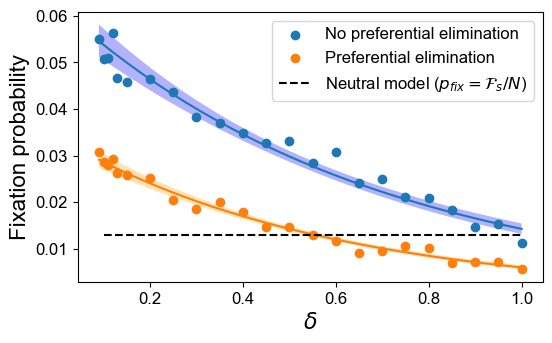

In [58]:
fixation_probabilities = np.load("./data_preprocessing/SSD_data/fixation_probabilities.npy")/10000
fixation_probabilities_pd = np.load("./data_preprocessing/SSD_data/fixation_probabilities_pref_deg.npy")/10000
deltas = np.array([0.09,0.1,0.11,0.12,0.13,0.15,0.2,0.25,0.3,0.35,0.4,0.45,0.5,0.55,0.6,0.65,0.7,0.75,0.8,0.85,0.9,0.95,1])
import statsmodels.api as sm
x = np.linspace(0.09,1,30)

plt.figure(1, figsize = (6,3.5))
mod = sm.OLS(np.log(fixation_probabilities), np.array([np.ones(len(deltas)), deltas]).transpose())
fii = mod.fit()
predictions = fii.get_prediction(np.array([np.ones(len(x)), x]).transpose())
plt.plot(x, np.exp(predictions.predicted_mean))
# Confidence interval for the mean line (obs=False is default)
ci_mean = predictions.conf_int(obs=False)
plt.fill_between(x, np.exp(ci_mean[:,0]), np.exp(ci_mean[:,1]), alpha = 0.3, facecolor = "blue")

mod = sm.OLS(np.log(fixation_probabilities_pd), np.array([np.ones(len(deltas)), deltas]).transpose())
fii = mod.fit()
predictions = fii.get_prediction(np.array([np.ones(len(x)), x]).transpose())
plt.plot(x, np.exp(predictions.predicted_mean))
# Confidence interval for the mean line (obs=False is default)
ci_mean = predictions.conf_int(obs=False)
plt.fill_between(x, np.exp(ci_mean[:,0]), np.exp(ci_mean[:,1]), alpha = 0.3, facecolor = "orange")

plt.scatter(deltas,fixation_probabilities, label = "No preferential elimination")
plt.scatter(deltas,fixation_probabilities_pd, label = "Preferential elimination")
plt.hlines((pi_y[6]/f_y[6])*1/100, 0.1,1, color = "black", linestyle = "dashed", label = "Neutral model ($p_{fix}=\mathcal{F}_s/N$)")

plt.xlabel("$\delta$")
plt.ylabel("Fixation probability")
plt.legend()